# Run-off by daily compounding: the LiST golden of 12.11% after 125 days

- **Level:** 2, The method in practice
- **Prerequisites:** notebook 01 of this topic (the ladder, the NLP and the survival period)
- **Reading time:** about 40 minutes

## Objectives

By the end of this notebook you can:

- state the cumulative outflow of a constant daily run-off rate, $1-(1-q)^n$, and reproduce the golden value of the ECB's liquidity stress test (12.11% after 125 days) with every intermediate;
- invert it, to turn an observed run ("85% in 2 days") into the daily rate that produces it, and see how far apart the runs of Table A.1 are;
- build the outflows of a segment day by day, with the contractual roll-off and the rule of no roll-over of financial deposits;
- back-test a modelled outflow against an observed run and read the traffic light.

## Setup

Install the pinned environment once, in a virtual environment, with the familiar command:

```bash
pip install -r notebooks/requirements.txt
```

or only the packages this notebook uses, with the same exact pins:

```bash
pip install riskvalidation==1.0.0 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` on Windows) builds `.venv-notebooks` for you. The next cell imports the packages and prints their versions.

In [1]:
# Import the tools and print the versions they run with, to compare them with notebooks/requirements.txt
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv

for name in ("riskvalidation", "numpy", "scipy", "matplotlib"):
    print(name, md.version(name))

riskvalidation 0.9.0
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Data

Two committed documents of case C16 (the balance sheet of the bank that failed on 2023-03-10: real FDIC call-report aggregates, synthetic behaviour and deposits, licence class `mirror-allowed`):

- `data/derived/C16/list-adverse.json`: the daily outflows of each deposit segment under the ECB LiST 2019 Adverse run-off, and the scoring against the run of March 2023.
- `data/derived/C16/lcr-standard.json`: the committed test rows of the run-off tests (the LiST golden and the back-test against the 30-day LCR outflows).

The run-off rates are the transcribed Tables 3.2 and 3.3 of the ECB's methodological note, held by the engine as module data (`LIST_PARAMETERS`); the observed runs are Table A.1 of the BCBS report on the 2023 turmoil (`TABLE_A1`).

In [2]:
# Load the two committed documents (the notebook sits three folders below the repository root)
ROOT = Path("../../..").resolve()
adverse = json.loads((ROOT / "data" / "derived" / "C16" / "list-adverse.json").read_text(encoding="utf-8"))
standard = json.loads((ROOT / "data" / "derived" / "C16" / "lcr-standard.json").read_text(encoding="utf-8"))
out = adverse["outputs"]

for name, doc in (("list-adverse", adverse), ("lcr-standard", standard)):
    print(name, "| baked by riskvalidation", doc["provenance"]["riskvalidation_version"], "| installed", rv.__version__)

list-adverse | baked by riskvalidation 0.9.0 | installed 0.9.0
lcr-standard | baked by riskvalidation 0.9.0 | installed 0.9.0


## Method

### Step 1: the cumulative outflow of a constant daily rate

The open-maturity deposits of the LiST (sight deposits with no contractual end) run off at a constant daily compounding rate $q$ on the stock of the day before, counted on relevant days (ECB, 2019, methodological note, Table 3.3, paragraph 107). After $n$ days the cumulative outflow share is:

$$F(n) = 1 - (1 - q)^n$$

The golden value is the note's own example: stable retail deposits under the Adverse shock have $q = 0.103258\%$ per relevant day, and the six months have $n = 125$ relevant days, which gives $F(125) \approx 12.11\%$. The next cell shows the three intermediates (the base $1-q$, its power and the complement) and then calls `cumulative_outflow_constant`.

In [3]:
# The golden example of the LiST note: every intermediate, then the engine
from riskvalidation.liquidity.runoff import LIST_PARAMETERS, cumulative_outflow_constant

q = LIST_PARAMETERS["adverse"]["open_maturity"]["stable-retail"]
n = 125
base = 1.0 - q
power = base ** n
by_hand = 1.0 - power
engine = cumulative_outflow_constant(q, n)

print("q =", q, "| n =", n)
print("1 - q =", round(base, 8))
print("(1 - q)^n =", round(power, 8))
print("1 - (1 - q)^n =", round(by_hand, 8))
print("engine:", round(engine, 8), "| equal:", bool(np.isclose(by_hand, engine)))

q = 0.00103258 | n = 125
1 - q = 0.99896742
(1 - q)^n = 0.87885163
1 - (1 - q)^n = 0.12114837
engine: 0.12114837 | equal: True


This is a check of the equation on one number, not a second implementation: the engine's function also validates its inputs (a rate in $[0,1]$, a non-negative integer number of days) and accepts arrays. The product wraps the golden as a validation test, `liq.list_compounding_golden`, whose statistic is the distance to the printed value. The next cell calls it and sets it beside the row committed in `lcr-standard.json`, with the engine version that baked that row.

In [4]:
# The golden as a TestResult, and the committed row of the same test
from riskvalidation.validation.liquidity import list_compounding_golden

golden = list_compounding_golden()
rows = {row["test_id"]: row for row in standard["tests"] if row["segment"] is None}
committed = rows["liq.list_compounding_golden"]

print("test_id:", golden.test_id)
print("cumulative outflow:", round(golden.metric, 8), "| distance to the printed value:", golden.statistic, "| n =", golden.n)
print("light:", golden.light.value, "| committed row:", committed["light"], "| baked by", standard["provenance"]["riskvalidation_version"])
print("same statistic as the committed row:", bool(np.isclose(golden.statistic, committed["statistic"])))

test_id: liq.list_compounding_golden
cumulative outflow: 0.12114837 | distance to the printed value: 3.6571242759131373e-07 | n = 125
light: green | committed row: green | baked by 0.9.0
same statistic as the committed row: True


### Step 2: the inverse, from an observed run to a daily rate

An observed run is reported as a share $F$ of the deposits lost in $n$ days. The constant daily rate that compounds to it is the inverse of the equation above:

$$q = 1 - (1 - F)^{1/n}$$

Table A.1 of the BCBS report on the 2023 turmoil (BCBS, 2023) lists nine runs, from Northern Rock in 2007 to Silicon Valley Bank in 2023. The engine holds them as `TABLE_A1` and computes each implied rate with `daily_rate_from_cumulative`. The Federal Reserve's review of the bank (Federal Reserve, 2023) is the source of the 85% in two days. The next cell lists the rows from the slowest to the fastest and checks the round trip.

In [5]:
# The implied daily rate of each run of Table A.1, and the round trip through the forward equation
from riskvalidation.liquidity.runoff import TABLE_A1, daily_rate_from_cumulative

table = sorted(TABLE_A1, key=lambda r: r.implied_daily_rate)
print(f"{'bank':16s}{'year':>6s}{'outflow':>10s}{'days':>6s}{'daily rate':>14s}{'round trip':>14s}")
for run in table:
    q_run = daily_rate_from_cumulative(run.outflow_share, run.days)
    back = cumulative_outflow_constant(q_run, run.days)
    print(f"{run.bank:16s}{run.year:6d}{run.outflow_share:10.2f}{run.days:6d}{q_run:14.6f}{back:14.6f}")

fastest, slowest = table[-1], table[0]
print("fastest over slowest:", round(fastest.implied_daily_rate / slowest.implied_daily_rate, 1))

bank              year   outflow  days    daily rate    round trip
Credit Suisse     2023      0.21    90      0.002616      0.210000
Icesave           2008      0.20    75      0.002971      0.200000
IndyMac           2008      0.08    14      0.005938      0.080000
First Republic    2023      0.57    90      0.009334      0.570000
WaMu              2008      0.10    10      0.010481      0.100000
Northern Rock     2007      0.20     4      0.054258      0.200000
Signature         2023      0.20     1      0.200000      0.200000
SVB UK            2023      0.30     1      0.300000      0.300000
SVB               2023      0.85     2      0.612702      0.850000
fastest over slowest: 234.2


### Step 3: the outflows of a segment, day by day

When the rate changes with the state of the stress, the cumulative outflow is the product of the daily survivals, and the outflow of day $d$ is the stock still deposited times that day's rate:

$$F(n) = 1 - \prod_{d \le n} (1 - q_d), \qquad O_s(d) = B_s \prod_{k < d} (1 - q_k)\; q_d$$

$B_s$ is the opening balance of segment $s$. The engine has `cumulative_outflow_path` for the first and `behavioural_outflows` for the second (it multiplies the stock share of the day before by the rate, so it never subtracts two nearly equal numbers). The next cell rebuilds the retail insured segment of the document from its opening balance and its 125 daily rates, and prints the first three days as the intermediates.

In [6]:
# Rebuild the retail insured segment from its opening balance and daily rates, and compare with the document
from riskvalidation.liquidity.ladder import behavioural_outflows
from riskvalidation.liquidity.runoff import cumulative_outflow_path

segments = {s["segment"]: s for s in out["path"]["ladder"]["segments"]}
retail = segments["retail-insured"]
opening = np.array([retail["opening_balance"]])
rates = np.array([retail["daily_rates"]])
flows = behavioural_outflows(opening, rates)[0]
cumulative = cumulative_outflow_path(rates[0])

print("opening balance (USD thousands):", opening[0], "| days:", rates.shape[1], "| daily rate of day 1:", rates[0, 0])
survival = 1.0
for day in range(3):
    print(f"day {day + 1} | share still deposited before {survival:.8f} | rate {rates[0, day]} | outflow {opening[0] * survival * rates[0, day]:.4f} | engine {flows[day]:.4f}")
    survival *= 1.0 - rates[0, day]
print("same outflows as the document:", bool(np.allclose(flows, retail["outflows"])))
print("same cumulative share:", bool(np.allclose(cumulative, retail["cumulative_outflow_share"])), "|", round(cumulative[-1], 6))
print("outflows add up to opening x cumulative share:", bool(np.isclose(flows.sum(), opening[0] * cumulative[-1])))

opening balance (USD thousands): 9990000.0 | days: 125 | daily rate of day 1: 0.00373218
day 1 | share still deposited before 1.00000000 | rate 0.00373218 | outflow 37284.4782 | engine 37284.4782
day 2 | share still deposited before 0.99626782 | rate 0.00373218 | outflow 37145.3258 | engine 37145.3258
day 3 | share still deposited before 0.99254957 | rate 0.00373218 | outflow 37006.6928 | engine 37006.6928
same outflows as the document: True
same cumulative share: True | 0.373368
outflows add up to opening x cumulative share: True


The same two functions take a rate that changes. As an exploration, not a committed scenario, the next cell doubles the rate of this segment from day 11 to day 20 and compares the cumulative outflow at day 125 with the constant case: the path matters, not only the average rate.

In [7]:
# A rate that doubles on days 11 to 20 (an exploration, not a committed scenario)
what_if = rates[0].copy()
what_if[10:20] *= 2.0
path_what_if = cumulative_outflow_path(what_if)

print("cumulative outflow at day 125, constant rate:", round(cumulative[-1], 6))
print("cumulative outflow at day 125, doubled on days 11 to 20:", round(path_what_if[-1], 6))
print("extra outflow (USD thousands):", round(opening[0] * (path_what_if[-1] - cumulative[-1]), 2))

cumulative outflow at day 125, constant rate: 0.373368
cumulative outflow at day 125, doubled on days 11 to 20: 0.39645
extra outflow (USD thousands): 230597.75


### Step 4: contractual roll-off and the financial deposits

Not every liability is open-maturity. A contractual liability leaves the balance sheet when it matures, and the LiST applies to each maturing flow a constant outflow rate by class (Table 3.2, paragraph 94); the rest is assumed rolled over and stays beyond the horizon. Maturing interbank and other financial deposits do not roll over at all (paragraph 98, rate 1). The engine has `contractual_rolloff` and `financial_no_rollover`; the sight deposits of financial customers flow out in full on the first relevant day (paragraph 111), which is how the document runs its `financial` segment. The next cell shows the three rules.

In [8]:
# Contractual roll-off of a maturing flow, the no-roll-over rule and the financial segment of the document
from riskvalidation.liquidity.runoff import contractual_rolloff, financial_no_rollover

maturing = np.array([100.0, 50.0])
contractual = LIST_PARAMETERS["adverse"]["contractual_outflow"]
print("contractual outflow rates, Adverse:", {k: contractual[k] for k in ("stable-retail", "other-retail", "non-operational-credit-institutions")})
print("a flow of [100, 50] maturing, stable retail:", contractual_rolloff(maturing, contractual["stable-retail"]))
print("the same flow, a financial deposit:", financial_no_rollover(maturing))

financial = segments["financial"]
horizon = len(financial["outflows"])
full = behavioural_outflows(np.array([financial["opening_balance"]]), np.ones((1, horizon)))[0]
print("financial segment, rate 1 every day:", full[:3], "| same as the document:", bool(np.allclose(full, financial["outflows"])))

contractual outflow rates, Adverse: {'stable-retail': 0.18, 'other-retail': 0.39, 'non-operational-credit-institutions': 1.0}
a flow of [100, 50] maturing, stable retail: [18.  9.]
the same flow, a financial deposit: [100.  50.]
financial segment, rate 1 every day: [13899000.        0.        0.] | same as the document: True


### Step 5: the back-test against an observed run

A run-off assumption can be tested against what happened. The test `liq.runoff_adequacy_back_test` compares the modelled outflow share with the realised one (Basel assumptions against the observed rate):

$$\text{ratio} = \frac{\text{modelled share}}{\text{realised share}}, \qquad \text{shortfall} = \text{realised share} - \text{modelled share}$$

It is a descriptive score on one real event, with no p-value. The light is a Contraste internal gate (green from a ratio of 0.8, amber from 0.5, red below), not a regulatory threshold. The realised share is the Federal Reserve's "roughly 85 percent" of the deposit base in two days (Federal Reserve, 2023); the modelled share is the sum of the first two days of the segment outflows of the document over the model's deposit base. The next cell computes the modelled share and calls the test.

In [9]:
# Back-test the first two days of the LiST Adverse outflows against the observed 85 percent in two days
from riskvalidation.validation.liquidity import runoff_adequacy_back_test

scoring = out["scoring"]
base_deposits = scoring["model_deposit_base"]
first_two_days = sum(sum(s["outflows"][:2]) for s in out["path"]["ladder"]["segments"])
modelled = first_two_days / base_deposits
board = scoring["denominators"][0]

test = runoff_adequacy_back_test(modelled, board["realised_share"], compared_at="event-horizon", denominator=board["id"])
committed_rows = [row for row in adverse["tests"] if row["test_id"] == "liq.runoff_adequacy_back_test" and row["segment"] == board["id"]]

print("outflow of the first two days (USD thousands):", round(first_two_days, 2), "| deposit base of the model:", base_deposits)
print("modelled share:", round(modelled, 6), "| realised share:", board["realised_share"])
print("ratio:", round(test.statistic, 6), "| shortfall:", round(test.metric, 6), "| light:", test.light.value)
print("committed row:", round(committed_rows[0]["statistic"], 6), committed_rows[0]["light"], "| same ratio:", bool(np.isclose(test.statistic, committed_rows[0]["statistic"])))
compared = {"event-horizon": "event horizon", "model-horizon": "model horizon (30 days)"}
for row in standard["tests"]:
    if row["test_id"] == "liq.runoff_adequacy_back_test":
        print("lcr-standard |", row["segment"], "|", compared[row["policy_version"].split("compared_at=")[1]], "|", round(row["statistic"], 6), row["light"])

outflow of the first two days (USD thousands): 16053789.14 | deposit base of the model: 175481000.0
modelled share: 0.091484 | realised share: 0.85
ratio: 0.107629 | shortfall: 0.758516 | light: red
committed row: 0.107629 red | same ratio: True
lcr-standard | board-stated-share | model horizon (30 days) | 0.506405 amber
lcr-standard | call-report-dep | model horizon (30 days) | 0.539534 amber


The last cell draws the central lesson of the notebook. The smooth curves are the LiST Adverse cumulative outflows of three classes over 125 days; the points are the nine runs of Table A.1 at their own horizon. Every smooth curve sits below four of the five runs of 2023 (SVB, SVB UK, Signature and First Republic); only the run of Credit Suisse, 90 days long, lies below the two faster curves. The rates of the stress test describe a slow leak, the fast runs of 2023 describe something else.

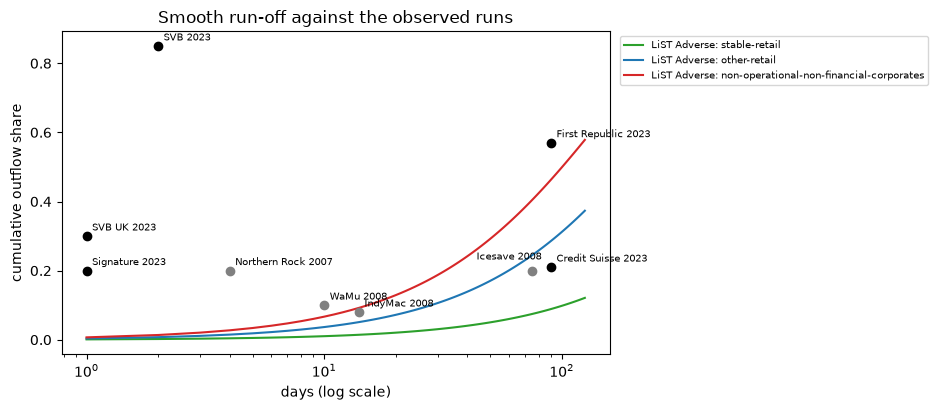

In [10]:
# Draw the smooth LiST Adverse curves against the runs of Table A.1
fig, ax = plt.subplots(figsize=(9.5, 4.2))
days = np.arange(1, 126)
for name, color in (("stable-retail", "tab:green"), ("other-retail", "tab:blue"), ("non-operational-non-financial-corporates", "tab:red")):
    ax.plot(days, cumulative_outflow_constant(LIST_PARAMETERS["adverse"]["open_maturity"][name], days), color=color, label=f"LiST Adverse: {name}")
for run in TABLE_A1:
    ax.scatter(run.days, run.outflow_share, color="black" if run.year == 2023 else "gray", zorder=3)
    ax.annotate(f"{run.bank} {run.year}", (run.days, run.outflow_share), textcoords="offset points", xytext=(-40, 8) if run.row_id == "icesave-2008" else (4, 4), fontsize=7)
ax.set_xscale("log")
ax.set_xlabel("days (log scale)")
ax.set_ylabel("cumulative outflow share")
ax.set_title("Smooth run-off against the observed runs")
ax.legend(fontsize=7, loc="upper left", bbox_to_anchor=(1.01, 1.0))
fig.tight_layout()
plt.show()

## Results

- **The golden.** The base, its 125th power and the complement are 0.99896742, 0.87885163 and 0.12114837, and the engine agrees. The product's golden test is green, at about 3.7e-07 from the printed 12.11%, and its statistic equals the one committed in `lcr-standard.json`.
- **The inverse.** The implied daily rate of the nine runs goes from 0.002616 (Credit Suisse, 21% in 90 days) to 0.612702 (SVB, 85% in 2 days): the fastest is 234.2 times the slowest, and every rate returns the share of the table on the round trip. The stable retail rate of the note, 0.00103258, is below even the slowest run of the table.
- **The segment.** The retail insured segment loses 37,284.48 thousand USD on day 1 and 37,145.33 on day 2 (the stock shrinks, the rate does not) and 0.373368 of its stock after 125 days; the engine and the document agree on the series and on the cumulative share, and the outflows add up to the opening balance times that share. Doubling the rate on days 11 to 20 raises the cumulative outflow from 0.373368 to 0.39645, which is 230,597.75 thousand USD more. A contractual flow of [100, 50] of stable retail rolls off as [18, 9], the same flow of a financial deposit leaves in full, and the financial segment of the document leaves 13,899,000 thousand USD on day 1.
- **The back-test.** The LiST Adverse outflow of the first two days is 16,053,789.14 thousand USD, 0.091484 of the deposit base of the model. Against the 0.85 of the Federal Reserve this is a ratio of 0.107629 and a shortfall of 0.758516, red under the internal gates; the engine and the committed row agree. Against the 30-day LCR outflows (the model horizon) the two committed rows are amber, with ratios of 0.506405 and 0.539534. The smooth assumption is far from the event it is asked to cover; the rows describe one real event with synthetic deposits, one observation and no p-value, so they show the size of the gap, not a probability.

What this notebook does not show: how the CBC that these outflows are set against is built (notebook 03), how the segments are composed into a scenario (notebook 04) or what the LCR says (notebook 05).

## Summary

- A constant daily rate $q$ compounds to $1-(1-q)^n$ after $n$ days; the LiST golden (12.11% after 125 days at 0.103258% a day) is reproduced to the printed precision.
- Its inverse turns any observed run into a daily rate, which puts very different runs on one scale.
- A segment's outflows are the stock still deposited times the daily rate; contractual liabilities roll off by class and financial deposits do not roll over.
- A back-test sets the modelled outflow against an observed run; under the product's internal gates the LiST Adverse outflow of the first two days is red against the 85% of March 2023.

**What to try next.** Change the day and the rate of the exploration (a doubling on days 1 to 5) and see how much of the cumulative outflow comes from the first week; then continue with notebook 03.

## References

- ECB Banking Supervision (2019), Sensitivity analysis of liquidity risk, stress test 2019, methodological note (2019-02-06), Tables 3.2 and 3.3 and paragraphs 94, 98, 107 and 111. https://www.bankingsupervision.europa.eu/ecb/pub/pdf/ssm.ECB_sensitivity_analysis_of_liquidity_risk-stress_test_2019-methodological_note_20190206~6771e88926.en.pdf
- BCBS (2023), Report on the 2023 banking turmoil, Box A, Table A.1. https://www.bis.org/bcbs/publ/d555.htm
- Federal Reserve Board (2023-04-28), Review of the Federal Reserve's Supervision and Regulation of Silicon Valley Bank. https://www.federalreserve.gov/publications/files/svb-review-20230428.pdf